<a href="https://colab.research.google.com/github/shivanishreesivaraj-png/thiruparankundram-analysis/blob/main/thiruparankuram_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

THIRUPARANKUNDRAM RESEARCH DATASET AUDIT
File: /content/thiruparankundram_academic_master_dataset.csv
Total records: 63
Total columns: 10
Missing values: 0
Missing value rate: 0.0 %
Duplicate rows: 0

Available columns:
 - record_id
 - domain_category
 - subject_site
 - title_event_description
 - date_or_period
 - authority_institution_court
 - legal_status_or_finding
 - source_url
 - verification_status
 - notes

Detected analysis columns:
Domain: domain_category
Title/description: title_event_description
Record ID: record_id
Verification status: verification_status
Evidence type: None
Date: date_or_period
Legal status: legal_status_or_finding
Site/location: None
Source title: None
Primary/secondary source: None

DOMAIN DISTRIBUTION
                           Domain  Record_Count  Percentage
       Source Validation Registry            15       23.81
              Historical Timeline            14       22.22
       Legal Records & Litigation            12       19.05
          Archae

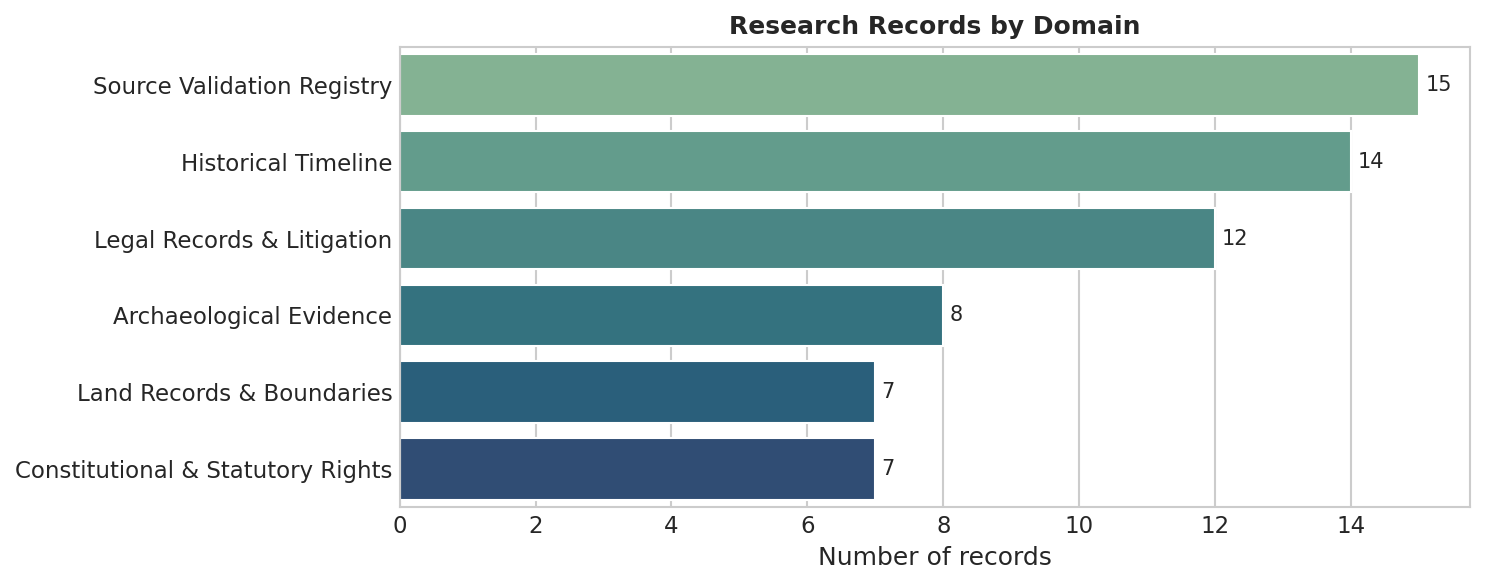

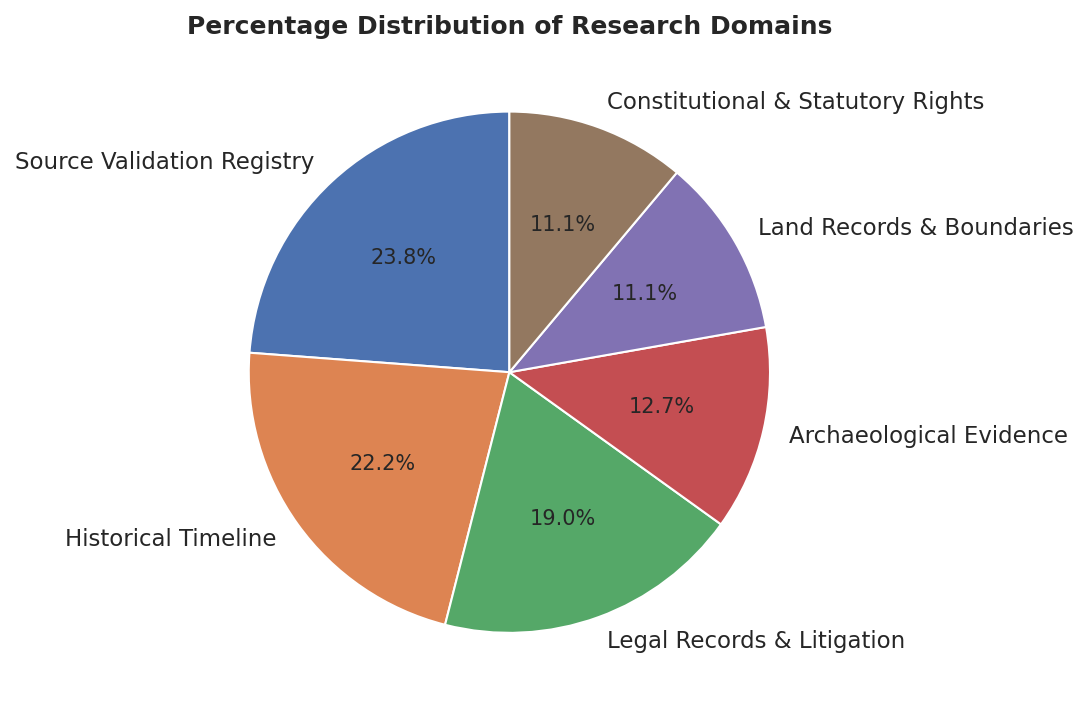


EVIDENCE VERIFICATION ANALYSIS
verification_status
Verified                                        54
Sub Judice / Pending                             7
UNVERIFIED (Dual Attribution)                    1
Verified (Location & Dual Typology recorded)     1
Name: count, dtype: Int64


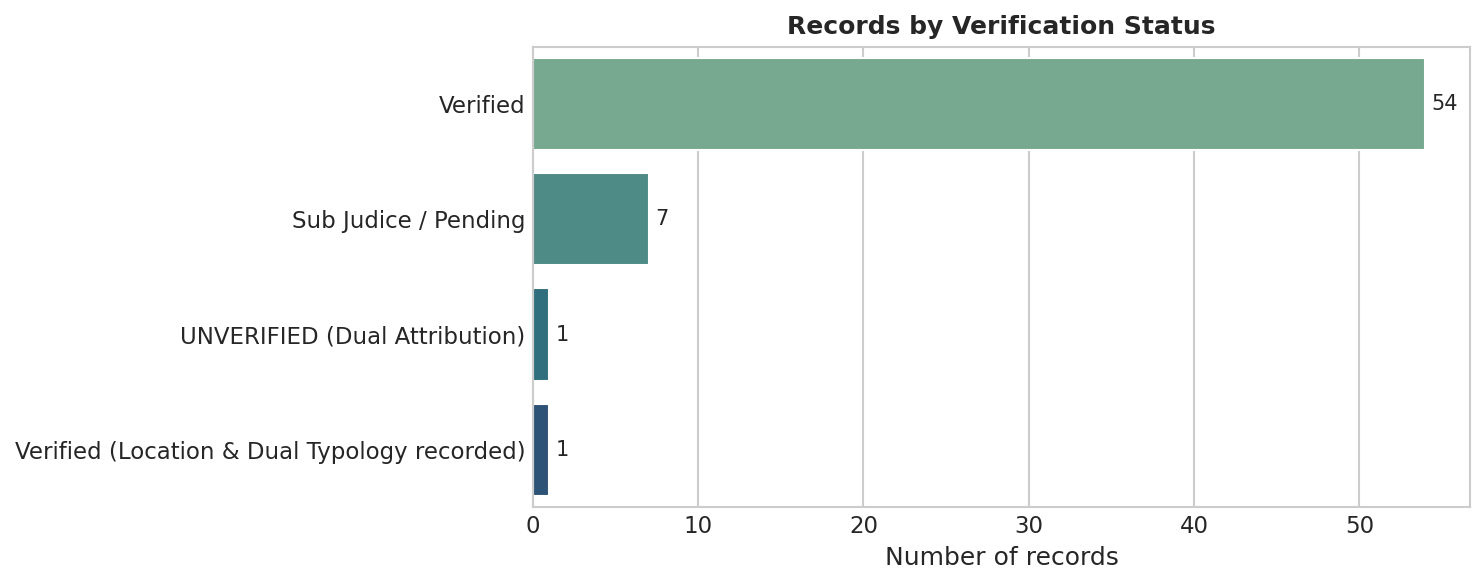

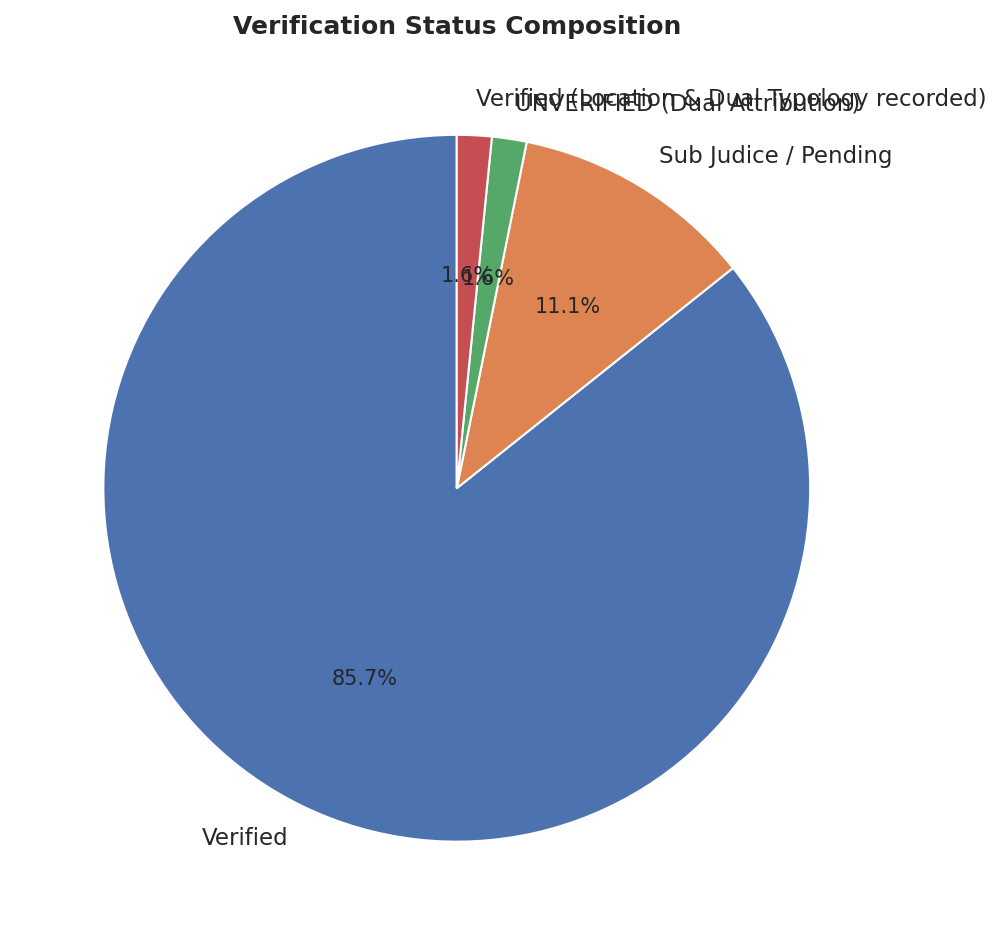


HISTORICAL / LITERARY REFERENCES
Matching records: 4
   record_id                                                                    title_event_description                              date_or_period verification_status
HIST-HIN-001         Sangam literary references to Murugankundram/Tenparankundram as 1st Arupadai Veedu -300 to 300 (Century Range - Sangam Period)            Verified
HIST-HIN-002 Excavation of main rock-cut cave temple for Shiva and Murugan by Minister Sattan Ganapathi      773 to 773 (Exact Year - Early Pandya)            Verified
     SRC-008                  Subject: Sangam Literature & Sacred Landscape | Tier: Secondary (Level 3)                      Publication Year: 2026            Verified
     SRC-014               Subject: Paripatal, Tirumurukarruppatai, Akananuru | Tier: Primary (Level 1)                      Publication Year: 1920            Verified

ARCHAEOLOGICAL RECORDS
Matching archaeological records: 8
record_id                                      

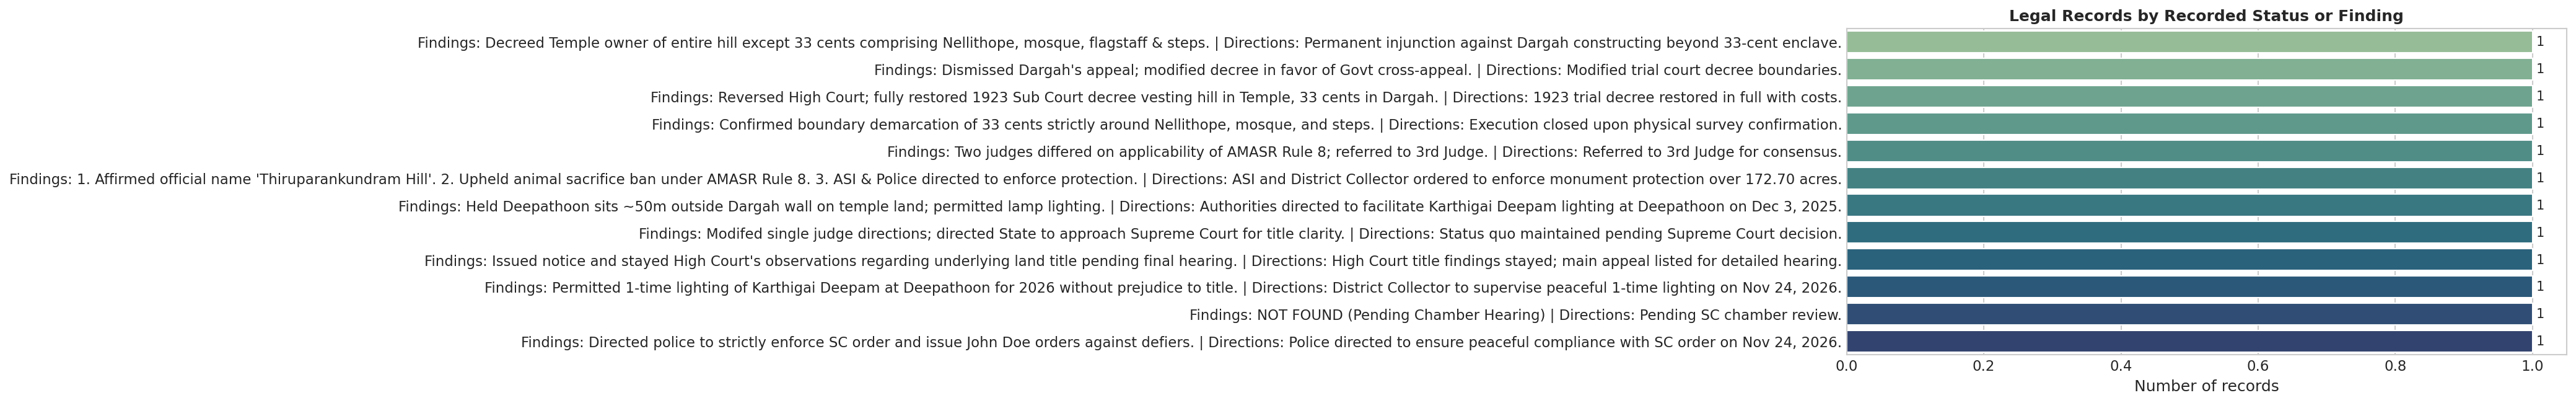


LAND RECORD ANALYSIS
Land/property records: 7


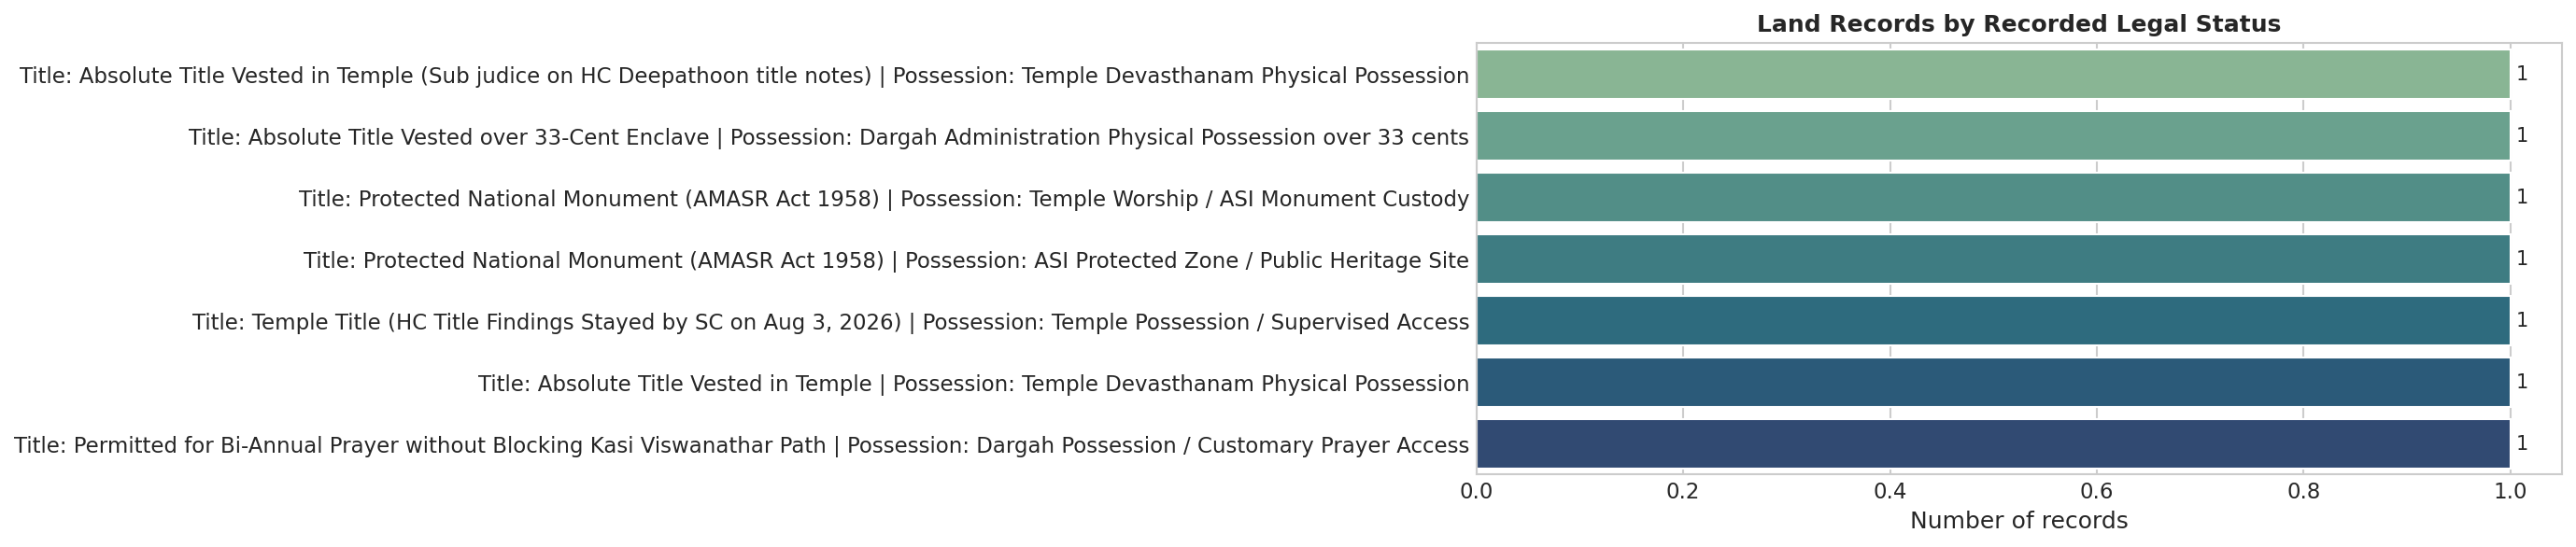


SOURCE ANALYSIS

CHRONOLOGY ANALYSIS


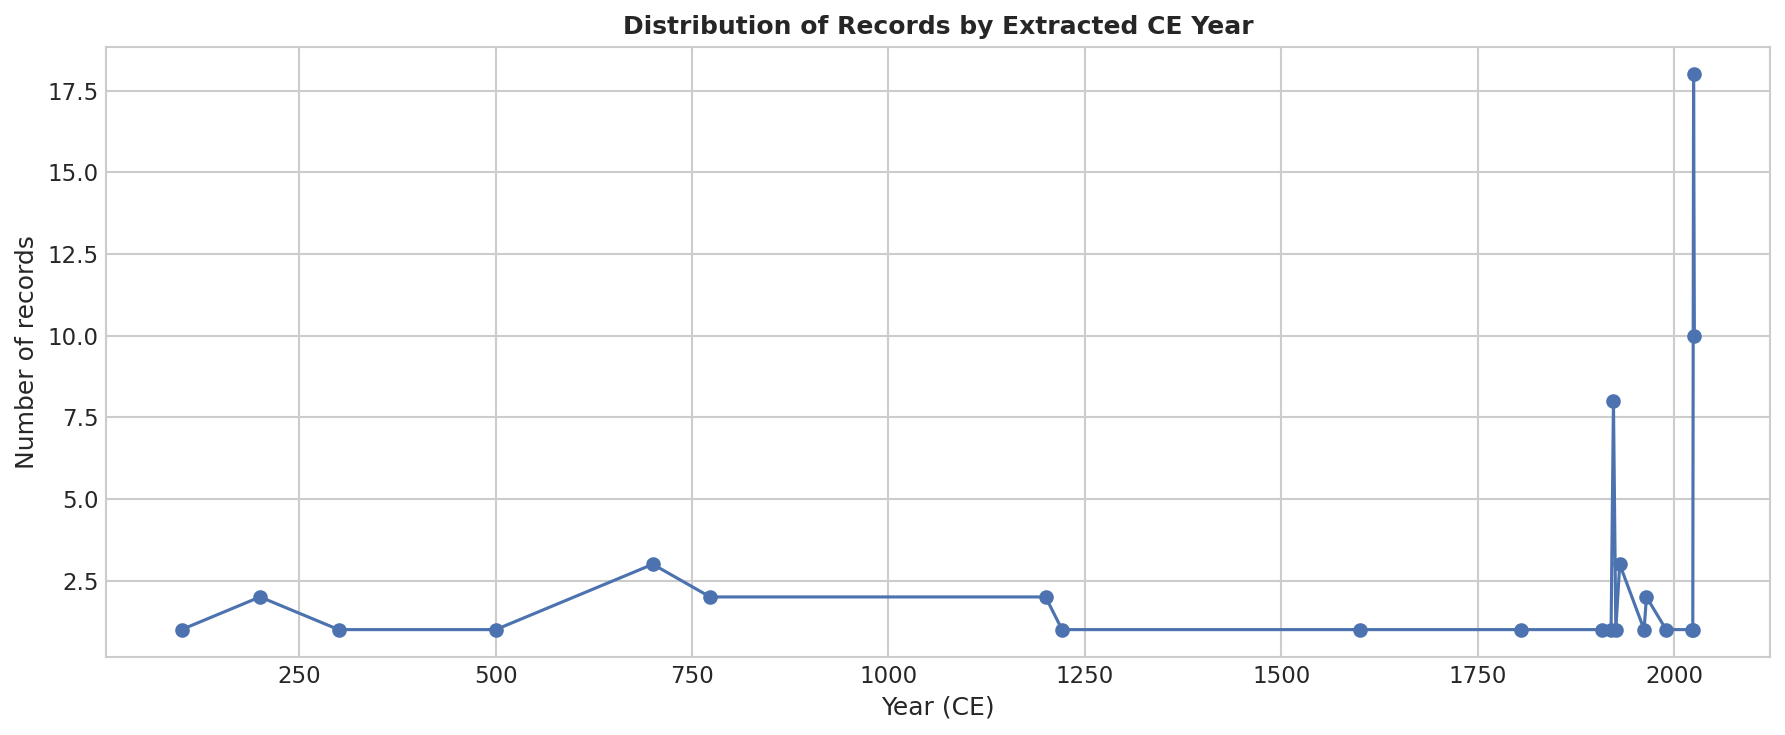

Records with extractable CE years: 63

CATEGORY CROSS-ANALYSIS
verification_status                Sub Judice / Pending  \
domain_category                                           
Archaeological Evidence                               0   
Constitutional & Statutory Rights                     0   
Historical Timeline                                   0   
Land Records & Boundaries                             0   
Legal Records & Litigation                            7   
Source Validation Registry                            0   

verification_status                UNVERIFIED (Dual Attribution)  Verified  \
domain_category                                                              
Archaeological Evidence                                        0         7   
Constitutional & Statutory Rights                              0         7   
Historical Timeline                                            1        13   
Land Records & Boundaries                                      0         7

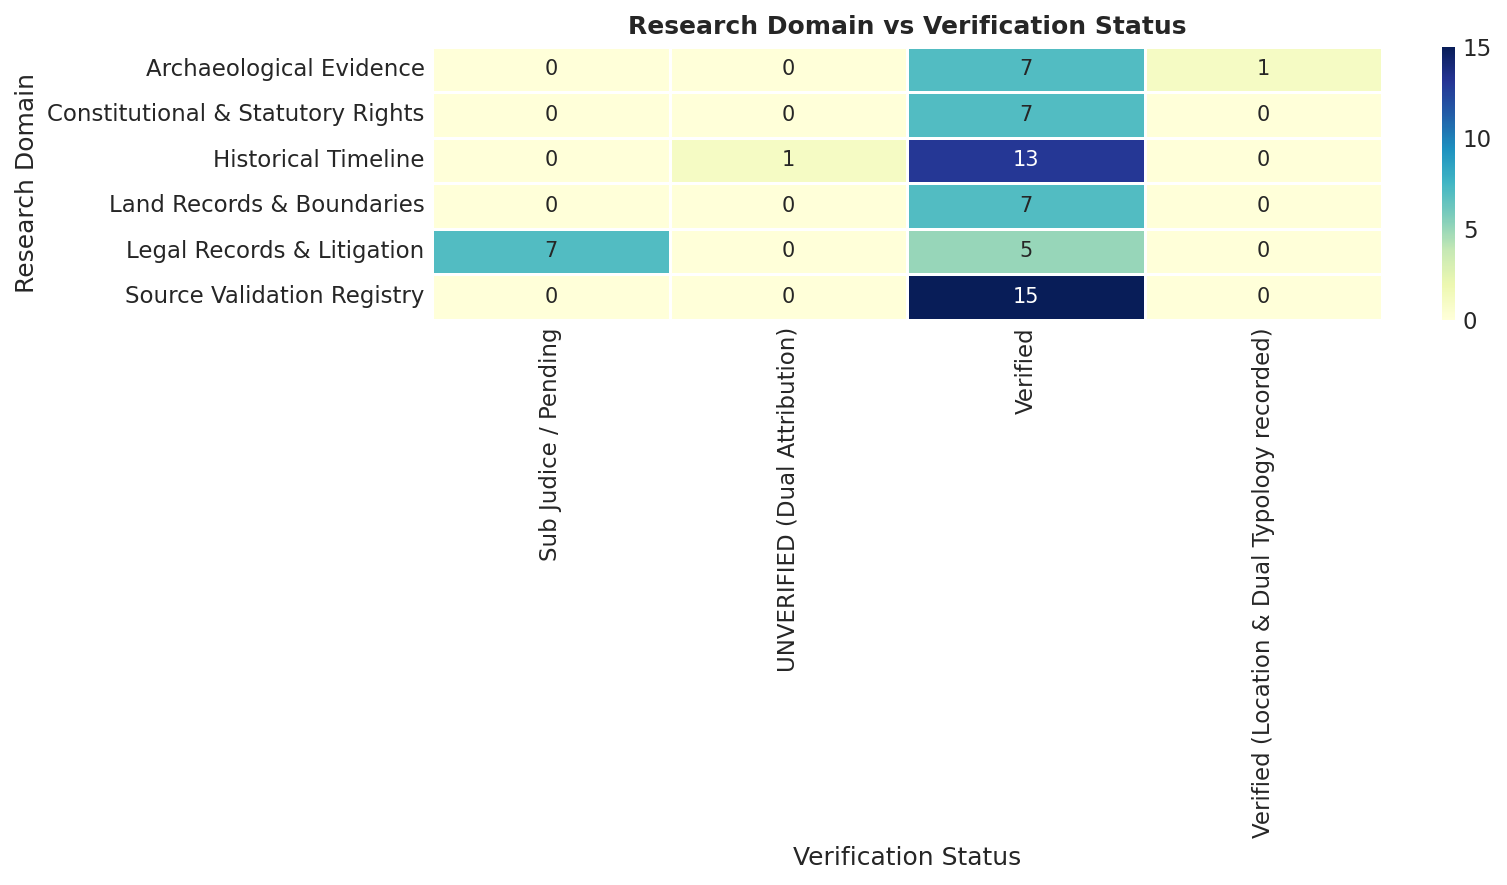

No missing values detected.

AUTOMATIC ANALYTICAL OBSERVATIONS
1. Dataset contains 63 records and 11 columns.
2. Total missing cells: 0.
3. Duplicate records removed during cleaning: 0.
4. Most represented domain: Source Validation Registry (15 records).
5. Most frequent verification label: Verified (54 records).

ANALYSIS COMPLETED
Charts and reports saved in: thiruparankundram_analysis

Generated files:
 - 01_domain_distribution.png
 - 02_domain_pie_chart.png
 - 03_verification_status.png
 - 04_verification_pie.png
 - 08_legal_status.png
 - 09_land_legal_status.png
 - 13_historical_chronology.png
 - 14_domain_verification_heatmap.png
 - analysis_interpretations.csv
 - archaeological_evidence_archaeological_institution_bar.png
 - archaeological_evidence_cleaned.csv
 - archaeological_evidence_confidence_bar.png
 - archaeological_evidence_correlation.png
 - archaeological_evidence_dating_method_bar.png
 - archaeological_evidence_evidence_id_bar.png
 - archaeological_evidence_evidence_ty

In [15]:

# =============================================================================
# THIRUPARANKUNDRAM: COMPREHENSIVE HISTORICAL, ARCHAEOLOGICAL & LEGAL ANALYSIS
# Complete, self-contained analysis
# =============================================================================

import os
import re
import glob
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# ---------------------------- 1. SETTINGS ------------------------------------

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["font.size"] = 10

OUTPUT_DIR = "thiruparankundram_analysis"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Find the master CSV automatically
possible_files = [
    "thiruparankundram_comprehensive_master_dataset.csv",
    "/workspace/artifacts/thiruparankundram_comprehensive_master_dataset.csv",
    "/content/thiruparankundram_comprehensive_master_dataset.csv"
]

csv_file = next((f for f in possible_files if os.path.exists(f)), None)

if csv_file is None:
    matches = (
        glob.glob("/content/*thiruparankundram*.csv") +
        glob.glob("/workspace/artifacts/*thiruparankundram*.csv")
    )
    if matches:
        csv_file = matches[0]

if csv_file is None:
    raise FileNotFoundError(
        "Master CSV not found. Upload your CSV to Colab and run this cell again."
    )

df = pd.read_csv(csv_file)
df.columns = df.columns.str.strip()

print("=" * 70)
print("THIRUPARANKUNDRAM RESEARCH DATASET AUDIT")
print("=" * 70)
print("File:", csv_file)
print("Total records:", len(df))
print("Total columns:", len(df.columns))
print("Missing values:", df.isnull().sum().sum())
print("Missing value rate:", round(df.isnull().sum().sum() /
      max(df.size, 1) * 100, 2), "%")
print("Duplicate rows:", df.duplicated().sum())

print("\nAvailable columns:")
for col in df.columns:
    print(" -", col)

# ---------------------------- 2. CLEANING ------------------------------------

# Standardize text fields without changing original meaning
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace({
        "": pd.NA,
        "nan": pd.NA,
        "None": pd.NA,
        "N/A": pd.NA
    })

# Remove fully duplicated records
df = df.drop_duplicates().copy()

# Flexible column matching
def find_column(candidates):
    lookup = {c.lower().replace(" ", "_"): c for c in df.columns}
    for candidate in candidates:
        key = candidate.lower().replace(" ", "_")
        if key in lookup:
            return lookup[key]
    return None

domain_col = find_column(["domain_category", "domain", "category"])
title_col = find_column([
    "title_event_description", "title", "event_description",
    "description", "record_title"
])
id_col = find_column(["record_id", "evidence_id", "case_id", "id"])
status_col = find_column([
    "verification_status", "verification", "evidence_status"
])
evidence_col = find_column([
    "evidence_type", "record_type", "document_type", "source_type"
])
date_col = find_column([
    "date_or_period", "date", "event_date", "judgment_date",
    "document_date", "publication_year"
])
legal_col = find_column([
    "legal_status_or_finding", "legal_status", "judicial_findings",
    "decision_status", "final_directions"
])
site_col = find_column(["site", "location", "place", "property_description"])
source_col = find_column([
    "source_title", "source_name", "institution", "author"
])
source_level_col = find_column([
    "primary_or_secondary", "source_level", "source_category"
])

print("\nDetected analysis columns:")
for name, value in {
    "Domain": domain_col,
    "Title/description": title_col,
    "Record ID": id_col,
    "Verification status": status_col,
    "Evidence type": evidence_col,
    "Date": date_col,
    "Legal status": legal_col,
    "Site/location": site_col,
    "Source title": source_col,
    "Primary/secondary source": source_level_col
}.items():
    print(f"{name}: {value}")

# ---------------------------- 3. CHART HELPERS -------------------------------

chart_number = 0

def save_chart(filename):
    plt.tight_layout()
    plt.savefig(
        os.path.join(OUTPUT_DIR, filename),
        dpi=250,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

def bar_chart(series, title, xlabel, filename, horizontal=False,
              top_n=20):
    global chart_number

    values = series.dropna().astype(str).value_counts().head(top_n)

    if values.empty:
        print("Skipped:", title, "- no usable data.")
        return

    plt.figure(figsize=(10, max(4, len(values) * 0.38)))

    if horizontal:
        ax = sns.barplot(
            x=values.values,
            y=values.index,
            hue=values.index,
            palette="crest",
            legend=False
        )
        ax.set_xlabel(xlabel)
        ax.set_ylabel("")
        for container in ax.containers:
            ax.bar_label(container, padding=3)
    else:
        ax = sns.barplot(
            x=values.index,
            y=values.values,
            hue=values.index,
            palette="crest",
            legend=False
        )
        ax.set_ylabel(xlabel)
        ax.set_xlabel("")
        plt.xticks(rotation=35, ha="right")
        for container in ax.containers:
            ax.bar_label(container, padding=3)

    plt.title(title, fontweight="bold")
    save_chart(filename)

def pie_chart(series, title, filename, top_n=8):
    values = series.dropna().astype(str).value_counts().head(top_n)

    if values.empty:
        print("Skipped:", title)
        return

    plt.figure(figsize=(7, 7))
    plt.pie(
        values.values,
        labels=values.index,
        autopct="%1.1f%%",
        startangle=90
    )
    plt.title(title, fontweight="bold")
    save_chart(filename)

# ---------------------------- 4. DOMAIN ANALYSIS -----------------------------

print("\n" + "=" * 70)
print("DOMAIN DISTRIBUTION")
print("=" * 70)

if domain_col:
    domain_summary = (
        df[domain_col].value_counts(dropna=False)
        .rename_axis("Domain")
        .reset_index(name="Record_Count")
    )
    domain_summary["Percentage"] = (
        domain_summary["Record_Count"] / max(len(df), 1) * 100
    ).round(2)

    print(domain_summary.to_string(index=False))

    domain_summary.to_csv(
        os.path.join(OUTPUT_DIR, "domain_summary.csv"),
        index=False
    )

    bar_chart(
        df[domain_col],
        "Research Records by Domain",
        "Number of records",
        "01_domain_distribution.png",
        horizontal=True
    )

    pie_chart(
        df[domain_col],
        "Percentage Distribution of Research Domains",
        "02_domain_pie_chart.png"
    )
else:
    print("No domain/category column found.")

# ---------------------------- 5. VERIFICATION ANALYSIS -----------------------

print("\n" + "=" * 70)
print("EVIDENCE VERIFICATION ANALYSIS")
print("=" * 70)

if status_col:
    verification_summary = df[status_col].value_counts(dropna=False)
    print(verification_summary)

    bar_chart(
        df[status_col],
        "Records by Verification Status",
        "Number of records",
        "03_verification_status.png",
        horizontal=True
    )

    pie_chart(
        df[status_col],
        "Verification Status Composition",
        "04_verification_pie.png"
    )
else:
    print("Verification status column not available.")

# ---------------------------- 6. EVIDENCE TYPE ANALYSIS ----------------------

if evidence_col:
    print("\nEVIDENCE TYPE DISTRIBUTION")

    bar_chart(
        df[evidence_col],
        "Distribution of Evidence Types",
        "Number of records",
        "05_evidence_types.png",
        horizontal=True
    )

    pie_chart(
        df[evidence_col],
        "Evidence Type Composition",
        "06_evidence_type_pie.png"
    )

# ---------------------------- 7. HISTORICAL REFERENCES -----------------------

print("\nHISTORICAL / LITERARY REFERENCES")

if title_col:
    search_pattern = (
        r"Sangam|Parip[aā]ṭal|Paripatal|Tirumuruk|"
        r"Akananuru|Akam|Murugan"
    )

    historical_df = df[
        df[title_col].astype("string").str.contains(
            search_pattern,
            case=False,
            na=False,
            regex=True
        )
    ].copy()

    print("Matching records:", len(historical_df))

    display_cols = [
        c for c in [id_col, title_col, date_col, status_col]
        if c is not None
    ]

    if not historical_df.empty:
        print(historical_df[display_cols].to_string(index=False))

        historical_df.to_csv(
            os.path.join(OUTPUT_DIR, "historical_literary_records.csv"),
            index=False
        )
else:
    print("Title/description column not available.")

# ---------------------------- 8. ARCHAEOLOGICAL ANALYSIS ---------------------

print("\nARCHAEOLOGICAL RECORDS")

if domain_col:
    archaeological_df = df[
        df[domain_col].astype("string").str.contains(
            "Archaeolog|Epigraph|Inscription|Monument",
            case=False,
            na=False
        )
    ].copy()

    print("Matching archaeological records:", len(archaeological_df))

    if title_col and not archaeological_df.empty:
        cols = [
            c for c in [id_col, title_col, date_col, status_col]
            if c is not None
        ]
        print(archaeological_df[cols].to_string(index=False))

    if evidence_col and not archaeological_df.empty:
        bar_chart(
            archaeological_df[evidence_col],
            "Archaeological Evidence by Type",
            "Number of records",
            "07_archaeological_evidence_types.png",
            horizontal=True
        )

    archaeological_df.to_csv(
        os.path.join(OUTPUT_DIR, "archaeological_records.csv"),
        index=False
    )

# ---------------------------- 9. LEGAL ANALYSIS ------------------------------

print("\nLEGAL RECORD ANALYSIS")

if domain_col:
    legal_df = df[
        df[domain_col].astype("string").str.contains(
            "Legal|Court|Judicial|Case",
            case=False,
            na=False
        )
    ].copy()

    print("Legal records:", len(legal_df))

    if title_col and not legal_df.empty:
        cols = [
            c for c in [id_col, title_col, date_col, legal_col, status_col]
            if c is not None
        ]
        print(legal_df[cols].to_string(index=False))

    if legal_col and not legal_df.empty:
        bar_chart(
            legal_df[legal_col],
            "Legal Records by Recorded Status or Finding",
            "Number of records",
            "08_legal_status.png",
            horizontal=True
        )

    if date_col and not legal_df.empty:
        legal_df.to_csv(
            os.path.join(OUTPUT_DIR, "legal_records.csv"),
            index=False
        )

# ---------------------------- 10. LAND RECORD ANALYSIS ----------------------

print("\nLAND RECORD ANALYSIS")

if domain_col:
    land_df = df[
        df[domain_col].astype("string").str.contains(
            "Land|Property|Ownership|Revenue",
            case=False,
            na=False
        )
    ].copy()

    print("Land/property records:", len(land_df))

    if not land_df.empty:
        if legal_col:
            bar_chart(
                land_df[legal_col],
                "Land Records by Recorded Legal Status",
                "Number of records",
                "09_land_legal_status.png",
                horizontal=True
            )

        if site_col:
            bar_chart(
                land_df[site_col],
                "Land Records by Site or Location",
                "Number of records",
                "10_land_locations.png",
                horizontal=True
            )

        land_df.to_csv(
            os.path.join(OUTPUT_DIR, "land_records.csv"),
            index=False
        )

# ---------------------------- 11. SOURCE QUALITY ANALYSIS -------------------

print("\nSOURCE ANALYSIS")

if source_level_col:
    bar_chart(
        df[source_level_col],
        "Distribution of Primary and Secondary Sources",
        "Number of sources",
        "11_primary_secondary_sources.png",
        horizontal=True
    )

if source_col:
    bar_chart(
        df[source_col],
        "Records by Source / Institution",
        "Number of records",
        "12_source_institutions.png",
        horizontal=True,
        top_n=15
    )

# ---------------------------- 12. CHRONOLOGY ANALYSIS ------------------------

print("\nCHRONOLOGY ANALYSIS")

if date_col:
    # Extract only clearly identifiable CE years.
    # BCE dates and century-only dates are not converted into modern dates.
    def extract_ce_year(value):
        if pd.isna(value):
            return np.nan

        text_value = str(value)

        if re.search(r"\bBCE\b|\bBC\b", text_value, re.I):
            return np.nan

        match = re.search(r"\b(1[0-9]{3}|20[0-9]{2}|[1-9][0-9]{2})\b",
                          text_value)

        return int(match.group(1)) if match else np.nan

    df["analysis_year"] = df[date_col].apply(extract_ce_year)

    chronology = df.dropna(subset=["analysis_year"]).copy()

    if not chronology.empty:
        yearly_counts = (
            chronology.groupby("analysis_year")
            .size()
            .sort_index()
        )

        plt.figure(figsize=(12, 5))
        plt.plot(
            yearly_counts.index,
            yearly_counts.values,
            marker="o"
        )
        plt.title(
            "Distribution of Records by Extracted CE Year",
            fontweight="bold"
        )
        plt.xlabel("Year (CE)")
        plt.ylabel("Number of records")
        save_chart("13_historical_chronology.png")

        yearly_counts.rename("Record_Count").to_csv(
            os.path.join(OUTPUT_DIR, "yearly_record_counts.csv")
        )

        print("Records with extractable CE years:", len(chronology))
    else:
        print("No extractable CE years found. Check the date format.")

# ---------------------------- 13. CATEGORY CROSS-ANALYSIS --------------------

print("\nCATEGORY CROSS-ANALYSIS")

if domain_col and status_col:
    cross_tab = pd.crosstab(
        df[domain_col],
        df[status_col],
        margins=False
    )

    print(cross_tab)

    plt.figure(figsize=(11, 6))
    sns.heatmap(
        cross_tab,
        annot=True,
        fmt="d",
        cmap="YlGnBu",
        linewidths=0.5
    )
    plt.title(
        "Research Domain vs Verification Status",
        fontweight="bold"
    )
    plt.xlabel("Verification Status")
    plt.ylabel("Research Domain")
    save_chart("14_domain_verification_heatmap.png")

    cross_tab.to_csv(
        os.path.join(OUTPUT_DIR, "domain_verification_crosstab.csv")
    )

if domain_col and evidence_col:
    evidence_cross_tab = pd.crosstab(
        df[domain_col],
        df[evidence_col]
    )

    plt.figure(figsize=(12, 6))
    sns.heatmap(
        evidence_cross_tab,
        annot=True,
        fmt="d",
        cmap="Blues",
        linewidths=0.5
    )
    plt.title(
        "Research Domain vs Evidence Type",
        fontweight="bold"
    )
    plt.xlabel("Evidence Type")
    plt.ylabel("Research Domain")
    save_chart("15_domain_evidence_heatmap.png")

# ---------------------------- 14. MISSING DATA ANALYSIS ----------------------

missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if not missing.empty:
    plt.figure(figsize=(10, max(4, len(missing) * 0.35)))
    sns.barplot(
        x=missing.values,
        y=missing.index,
        hue=missing.index,
        palette="mako",
        legend=False
    )
    plt.title("Missing Values by Column", fontweight="bold")
    plt.xlabel("Number of missing values")
    plt.ylabel("Column")
    save_chart("16_missing_values.png")
else:
    print("No missing values detected.")

# ---------------------------- 15. NUMERIC CORRELATION ------------------------

numeric_df = df.select_dtypes(include=np.number)

if numeric_df.shape[1] >= 2:
    correlation = numeric_df.corr()

    plt.figure(figsize=(10, 7))
    sns.heatmap(
        correlation,
        annot=True,
        cmap="coolwarm",
        center=0,
        fmt=".2f"
    )
    plt.title("Correlation Between Numeric Variables")
    save_chart("17_numeric_correlation.png")

# ---------------------------- 16. AUTOMATIC INTERPRETATIONS ------------------

interpretations = []

interpretations.append(
    f"Dataset contains {len(df)} records and {len(df.columns)} columns."
)

interpretations.append(
    f"Total missing cells: {df.isnull().sum().sum()}."
)

interpretations.append(
    f"Duplicate records removed during cleaning: "
    f"{pd.read_csv(csv_file).duplicated().sum()}."
)

if domain_col:
    most_common_domain = df[domain_col].value_counts().head(1)
    if not most_common_domain.empty:
        interpretations.append(
            f"Most represented domain: {most_common_domain.index[0]} "
            f"({most_common_domain.iloc[0]} records)."
        )

if status_col:
    most_common_status = df[status_col].value_counts().head(1)
    if not most_common_status.empty:
        interpretations.append(
            f"Most frequent verification label: "
            f"{most_common_status.index[0]} "
            f"({most_common_status.iloc[0]} records)."
        )

if evidence_col:
    most_common_evidence = df[evidence_col].value_counts().head(1)
    if not most_common_evidence.empty:
        interpretations.append(
            f"Most frequent evidence type: "
            f"{most_common_evidence.index[0]} "
            f"({most_common_evidence.iloc[0]} records)."
        )

print("\n" + "=" * 70)
print("AUTOMATIC ANALYTICAL OBSERVATIONS")
print("=" * 70)

for i, statement in enumerate(interpretations, 1):
    print(f"{i}. {statement}")

pd.DataFrame({
    "Analytical_Observation": interpretations
}).to_csv(
    os.path.join(OUTPUT_DIR, "analysis_interpretations.csv"),
    index=False
)

# ---------------------------- 17. EXPORT CLEANED DATA ------------------------

df.to_csv(
    os.path.join(OUTPUT_DIR, "cleaned_master_dataset.csv"),
    index=False
)

print("\n" + "=" * 70)
print("ANALYSIS COMPLETED")
print("=" * 70)
print("Charts and reports saved in:", OUTPUT_DIR)

print("\nGenerated files:")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print(" -", filename)

# Create a ZIP file containing all outputs
import shutil

zip_path = shutil.make_archive(
    "thiruparankundram_analysis_results",
    "zip",
    OUTPUT_DIR
)

print("\nZIP file created:", zip_path)
